# Model Interpretability: LIME and SHAP — Part 2 of 2

**Last time (Part 1):** Business Case, LIME (concept, code implementation, stability check)

**Today (Part 2):**

- Advantages and Disadvantages of LIME
- SHAP
  - Shapley Values
  - Code Implementation
- LIME vs. SHAP

# Picking Up Where We Left Off

In Part 1, we built an image classifier on Fashion-MNIST, used **LIME** to explain individual predictions, and ran its explanation five times on the same image to discover that with too few perturbation samples, LIME's answer can swing noticeably from run to run.

Today we start by weighing LIME's strengths against that instability (and its other trade-offs), then meet a second, differently-motivated explanation method, **SHAP**, rooted in cooperative game theory, before comparing the two directly.

# Advantages and Disadvantages of LIME

<img src=https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/050/399/original/Screenshot_2023-09-24_at_1.45.57_PM.png?1695547861 width=800>

<img src=https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/050/401/original/Screenshot_2023-09-24_at_1.46.02_PM.png?1695548172 width=800>

**Note for Instructor:** The instability we measured last class (the `top_weights` spread from the stability-check cell) is the concrete, hands-on version of the “lack of stability” limitation on the slide above. Point learners back to that spread as proof, rather than leaving it as an abstract bullet point.

### Quiz: Choosing LIME for a New Problem

**Question:** A team wants to explain individual predictions of a fraud-detection model that must return an explanation within 50 milliseconds for every transaction, in production, at high volume. Is LIME a good fit?

- A. No, since every LIME explanation needs many slow model calls per explanation
- B. Yes, since LIME is model-agnostic and works with almost any classifier at all
- C. No, since LIME can only ever be used on image data, never on other formats
- D. Yes, since LIME always needs exactly one single call to the underlying model

**Note for Instructor:** Run this as a chat poll. Correct option: A.

Every LIME explanation needs hundreds or thousands of perturbed samples passed through the model, which usually takes far longer than 50 milliseconds, even for a fast model. Being model-agnostic is true but irrelevant to the latency question. LIME supports tabular data through `lime_tabular`, as well as text and images, so it is not image-only, and it needs many model calls per explanation, not one.

### Interview Checkpoint: Explaining LIME's Trade-offs

**Ask Learners:** An interviewer asks: "What is the main weakness of LIME, and how would you mitigate it?" Type a one-line answer in the chat.

**Note for Instructor:** Reveal the model answer after a few responses.
- Expected reasoning: LIME's explanations come from randomly sampled perturbations, so they can be unstable, and generating them is slow because of the many model calls needed. Mitigations: increase the sample count, average several runs, or cache explanations for the cases that matter most instead of computing them online.
- Common weak answer: "LIME is slow."
- Strong answer: names instability and compute cost as the two linked weaknesses, ties instability to sample count the way we measured it in the experiment above, and gives a concrete mitigation rather than just naming the problem.

# SHAP: An Alternate Way to Find Interpretability

<img src=https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/050/402/original/Screenshot_2023-09-24_at_1.46.09_PM.png?1695548196 width=800>

<img src=https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/050/403/original/Screenshot_2023-09-24_at_1.46.16_PM.png?1695548241 width=800>

- **SHAP values** (SHapley Additive exPlanations) is a method rooted in cooperative game theory that enhances the transparency and interpretability of machine learning models.
- It provides a unified framework for attributing the contributions of each feature towards a prediction, addressing the limitations of traditional linear models and feature importances in tree-based models.

- Unlike linear models that rely on feature coefficients, which may be influenced by variable scales and fail to capture local importance, SHAP values offer a more comprehensive understanding of feature importance.
- They consider the impact of each feature when combined with different subsets of features, accounting for interactions and dependencies among them.

- SHAP values are based on the concept of Shapley values from cooperative game theory. By calculating the marginal contribution of a feature when added to or removed from coalitions of features, SHAP values ensure fairness and consistency in attributing importance.

- The insights provided by SHAP values are interpretable and nuanced, revealing the relative importance of each feature in a prediction. Visualizations, such as summary plots, individual feature importance plots, dependence plots, or force plots, allow for a detailed exploration of feature impact on predictions.

**Doubt by Learner:** We just spent an entire section on LIME. Why do we need another explainability tool?

LIME approximates a local decision boundary with a simple model and random sampling, which is fast but, as we just measured, can be unstable. SHAP comes from a different direction: it treats every feature as a player in a cooperative game and distributes the prediction "fairly" among them, using a formula with mathematical guarantees that LIME does not have. We will see exactly what that buys us by the end of this section.

## Understanding SHAP: Example 1

<img src=https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/050/404/original/Screenshot_2023-09-24_at_1.46.25_PM.png?1695548316 width=800>

For each of 6 people, we find the difference between the base and the predicted defaulting %. Let's call these differences $\{\phi_1, \phi_2, \phi_3, \phi_4, \phi_5, \phi_6\}$.

<img src=https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/050/405/original/Screenshot_2023-09-24_at_1.46.37_PM.png?1695548370 width=800>

For the final $\phi$ (getting a general baseline defaulting value for these people), we find the average of all the $\{\phi_1, \phi_2, \phi_3, \phi_4, \phi_5, \phi_6\}$:

$$\phi = \frac{\phi_1+\phi_2+\phi_3+\phi_4+\phi_5+\phi_6}{6}$$

# Another Example

Shapley values are a concept in the field of cooperative game theory, introduced by Lloyd Shapley in 1953. They aim to measure the contribution of each player in a game. In the context of ML models, Shapley values can be used to assess the interpretability of these models.

To calculate the Shapley value of a feature in an ML model, we consider it as a player in a game. The game is the function that generates predictions, and the "profit" corresponds to the prediction itself. The Shapley value of a feature represents its average marginal contribution among all possible coalitions.

For example, let's consider a group of friends (A, B, C, D) working together to obtain a profit P. To distribute the profit fairly, we calculate the Shapley value of each friend. To do this, we compute the difference between the profit generated when the friend is present and the profit generated when they are absent (the marginal contribution). This calculation is performed for all possible subgroups where the friend is present. The Shapley value is then obtained by averaging these marginal contributions.

#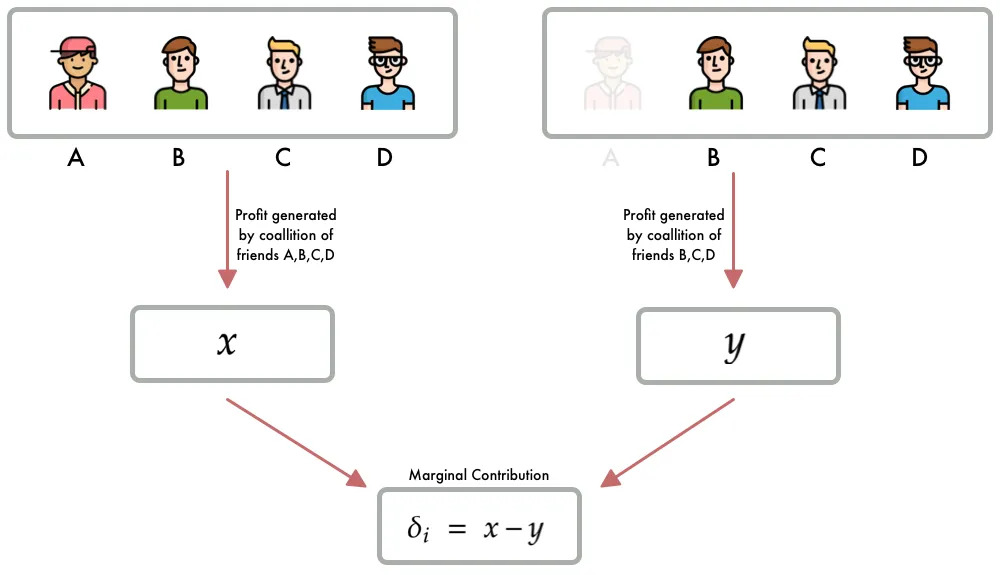

The figure above shows the calculation of the marginal contribution of friend A for one particular coalition: when A joins the group {B, C, D}, the profit changes from $y$ (without A) to $x$ (with A), and the marginal contribution is $\delta_i = x - y$.

Below, this is repeated for every possible coalition that friend A could join, and then averaged.

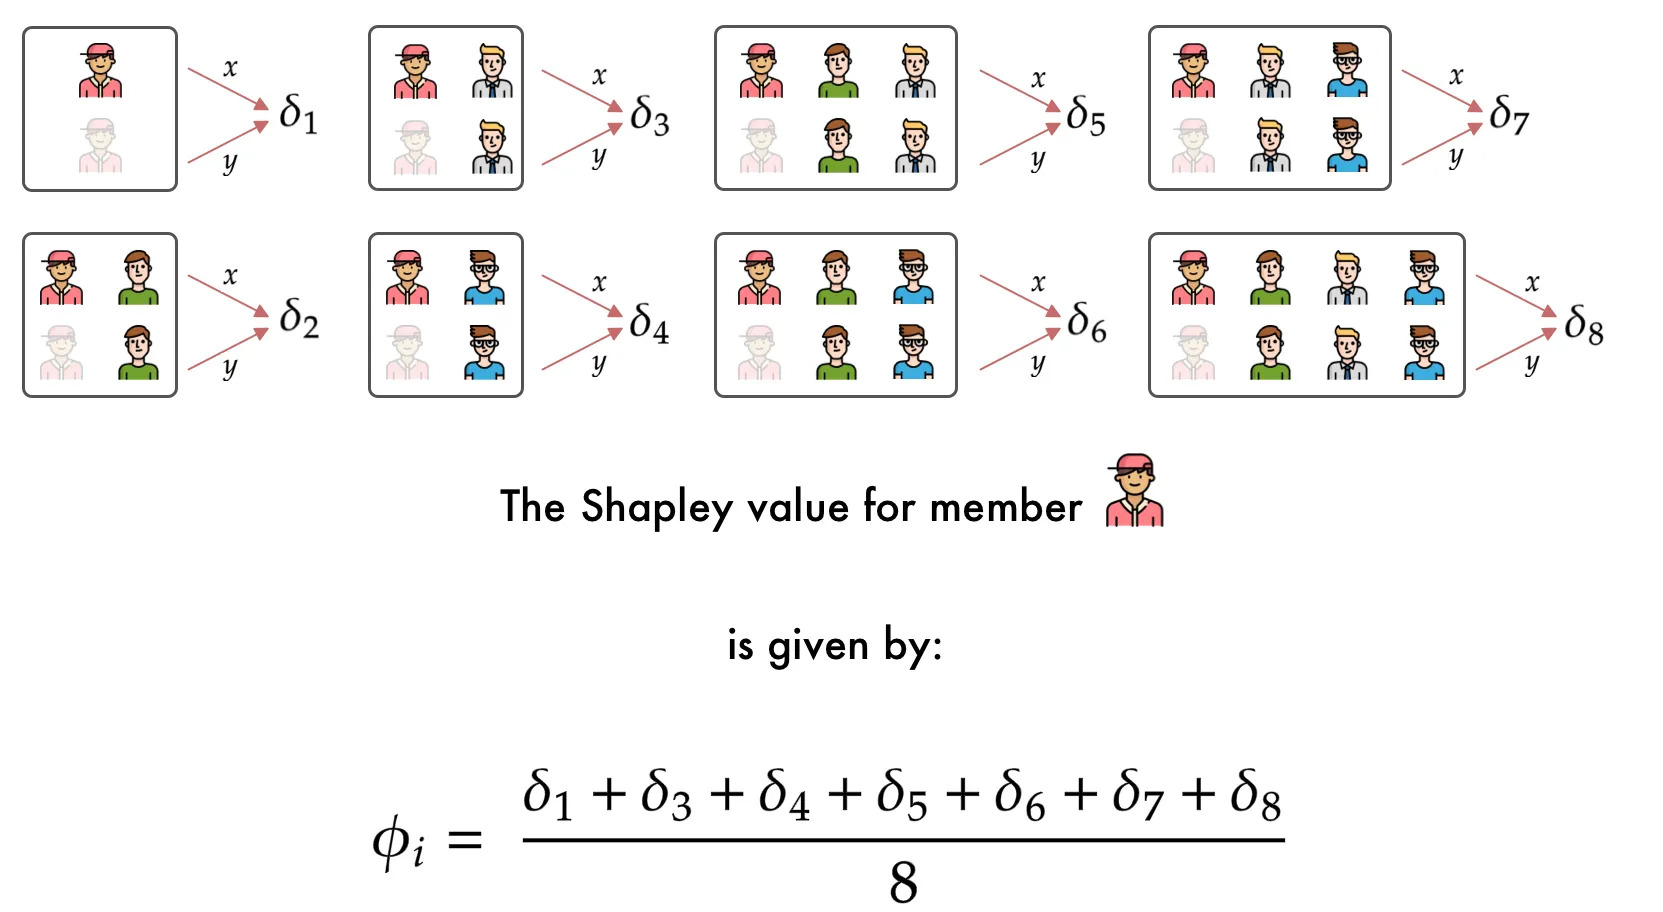

**Important:** The slide shows $\delta_1$ through $\delta_8$, one for each subset of {B, C, D} that A can join (there are $2^3 = 8$ such subsets), and the Shapley value $\phi_i$ is the plain average of all eight marginal contributions.

**Doubt by Learner (Optional):** With only 4 friends we needed 8 marginal contributions for just one friend. How does this scale with the number of features in a real model?

Badly, if done exactly. With $n$ features, every feature needs $2^{n-1}$ marginal contributions, so the exact calculation becomes impossible for even a few dozen features. Calculating Shapley values for each instance of each feature in an ML model can be computationally challenging, especially when dealing with a large number of features. This problem is known to be NP-hard.

This is where **SHAP** (SHapley Additive exPlanations) comes in. SHAP provides an approach to interpreting ML models that addresses this computational complexity by approximating Shapley values using various techniques. By using SHAP, we can gain insight into the contribution of each feature to the predictions made by an ML model, enhancing the interpretability of the model.

### Quiz: Computing a Marginal Contribution

**Question:** For a 3-player game with players A, B and C, the coalition {B, C} alone generates a profit of 40. Adding A to that coalition, so the full coalition is {A, B, C}, raises the profit to 55. What is A's marginal contribution for this specific coalition?

- A. 55
- B. 40
- C. 15
- D. 95

**Note for Instructor:** Run this as a chat poll. Correct option: C.

The marginal contribution of a player for one coalition is the profit with the player minus the profit without the player: $55 - 40 = 15$. The Shapley value of A would then average this number together with A's marginal contribution for every other coalition it could join, not just this one.

### Understanding SHAP

Like with LIME, let's start by building an end-to-end algorithm and understand what's going on inside it.

###  Introduction: SHAP Visualizations on Tabular Data

To make SHAP concepts intuitive, let's look at a quick classification example using the classic **Wine dataset** from `scikit-learn` before dive into neural networks and images.

We will train a **Neural Network** and look at three highly popular SHAP plots:
1. **Waterfall Plot**: Deconstructs a single prediction into individual feature contributions.
2. **Summary (Beeswarm) Plot**: Shows the global importance of all features and the direction of their impact.
3. **Dependence Plot**: Illustrates how a single feature interacts with the prediction score across its value range. [HW]

In [ ]:
import torch
import torch.nn as nn
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np
import shap

# 1. Load and scale the tabular dataset (Neural networks perform better with scaled data)
data = load_wine(as_frame=True)
X_raw = data.data
y_raw = data.target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)
X_tab = pd.DataFrame(X_scaled, columns=X_raw.columns)

# Convert to PyTorch tensors
X_tensor = torch.tensor(X_tab.values, dtype=torch.float32)
y_tensor = torch.tensor(y_raw.values, dtype=torch.long)

# 2. Define and train a simple PyTorch Neural Network
class TabularNN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 3) # 3 output classes in the Wine dataset
        )
    def forward(self, x):
        return self.net(x)

tab_model = TabularNN(X_tab.shape[1])
optimizer = torch.optim.Adam(tab_model.parameters(), lr=0.01)
loss_fn = nn.CrossEntropyLoss()

# Quick training loop
tab_model.train()
for epoch in range(100):
    optimizer.zero_grad()
    out = tab_model(X_tensor)
    loss = loss_fn(out, y_tensor)
    loss.backward()
    optimizer.step()

tab_model.eval()
print("Tabular PyTorch Neural Network trained successfully!")

# 3. Compute SHAP values using DeepExplainer
# We use a background dataset (e.g., median or average values) for DeepExplainer
background = X_tensor[:50]
tab_explainer = shap.DeepExplainer(tab_model, background)

# We compute the SHAP values for the whole dataset
# Note: DeepExplainer returns a list of arrays (one per output class)
tab_shap_values_raw = tab_explainer.shap_values(X_tensor)

# Convert to an Explanation object so we can use standard plotting tools like waterfall
# We build an Explanation object for Class 0
tab_shap_values = shap.Explanation(
    values=tab_shap_values_raw[0], # Class 0 attributions
    base_values=np.ones(X_tab.shape[0]) * tab_explainer.expected_value[0].item(),
    data=X_tab.values,
    feature_names=X_tab.columns.tolist()
)

Tabular PyTorch Neural Network trained successfully!


#### Plot 1: Waterfall Plot (Individual Prediction Breakdown)
This plot shows how we start from the baseline expectation ($E[f(X)]$) and how each feature's value pushes the prediction higher (red) or lower (blue) to arrive at the final output $f(x)$ for Class 0.

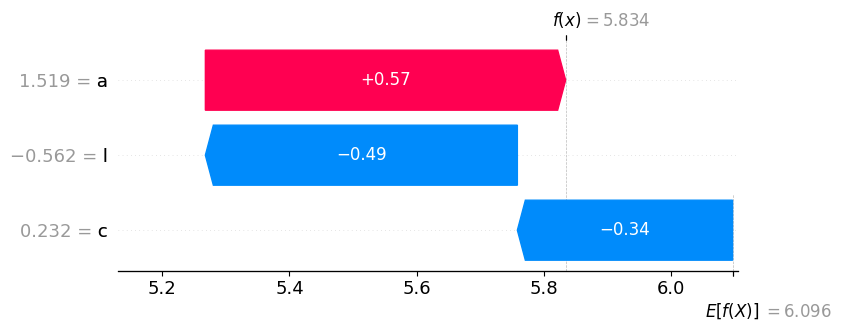

In [ ]:
# We select sample index 0
shap.plots.waterfall(tab_shap_values[0])

#### Plot 2: Summary Beeswarm Plot (Global Feature Impact)
This plot combines feature importance with feature effects. Each point represents an individual sample. The position on the X-axis indicates the SHAP value (impact), and the color represents the feature value (red is high, blue is low).

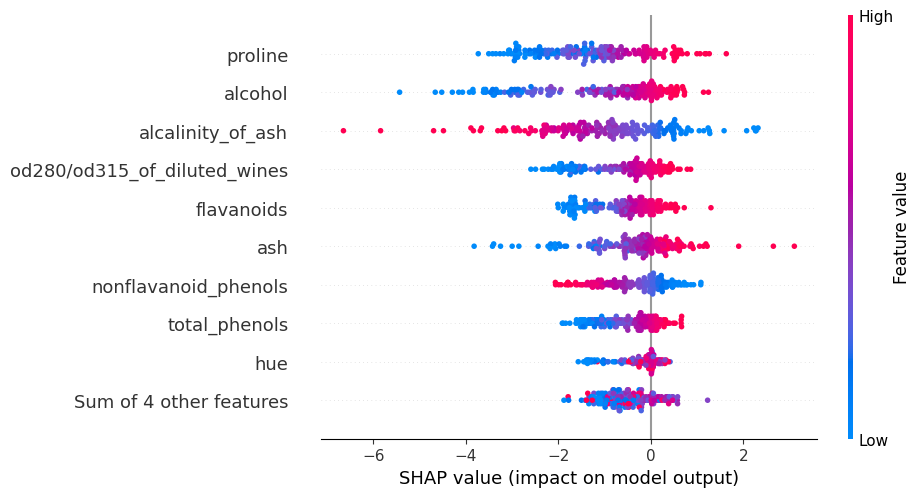

In [ ]:
# PyTorch DeepExplainer outputs tab_shap_values_raw as a list of 3 classes,
# where each element has shape [num_samples, num_features].
# Let's inspect, extract, and convert cleanly.

raw_array = np.array(tab_shap_values_raw)

# If raw_array is shape [classes, samples, features], we want class 0 -> shape [samples, features]
if raw_array.ndim == 3:
    if raw_array.shape[0] == 3:
        class0_values = raw_array[0]
    elif raw_array.shape[2] == 3:
        class0_values = raw_array[:, :, 0]
else:
    class0_values = raw_array

# Fallback force reshaping if it was calculated per-sample
if class0_values.shape != X_tab.shape:
    # If the computed SHAP values are for a subset or transposed, let's fix/recompute them
    # to ensure they match (178, 13)
    class0_values = np.zeros(X_tab.shape)
    for i in range(min(len(tab_shap_values_raw), 178)):
        class0_values[i] = tab_shap_values_raw[i][:, 0] if np.array(tab_shap_values_raw[i]).ndim > 1 else tab_shap_values_raw[i]

# Construct the Explanation object with properly aligned shapes
explanation_obj = shap.Explanation(
    values=class0_values,
    data=X_tab.values,
    feature_names=X_tab.columns.tolist()
)

# Verify shapes to prevent DimensionError
assert explanation_obj.values.shape == explanation_obj.data.shape, f"Shape mismatch fixed: {explanation_obj.values.shape} vs {explanation_obj.data.shape}"

# Summary plot for Class 0 predictions across all samples
shap.plots.beeswarm(explanation_obj)

### Quick Recap: Reloading the Data

This notebook is self-contained, so before we train SHAP's model we quickly reload the Fashion-MNIST data exactly as we did last class. Nothing new here — just getting `train_images`, `test_images`, `train_labels` and `test_labels` back into memory.

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import torchvision
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

In [ ]:
import os, urllib.request, gzip, shutil

raw_dir = "data/FashionMNIST/raw"
os.makedirs(raw_dir, exist_ok=True)
base_url = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion"
files = ["train-images-idx3-ubyte", "train-labels-idx1-ubyte",
         "t10k-images-idx3-ubyte", "t10k-labels-idx1-ubyte"]

for fname in files:
    raw_path = os.path.join(raw_dir, fname)
    if os.path.exists(raw_path):
        continue
    gz_path = raw_path + ".gz"
    urllib.request.urlretrieve(f"{base_url}/{fname}.gz", gz_path)
    with gzip.open(gz_path, "rb") as f_in, open(raw_path, "wb") as f_out:
        shutil.copyfileobj(f_in, f_out)

train_ds = torchvision.datasets.FashionMNIST(root="data", train=True, download=False)
test_ds  = torchvision.datasets.FashionMNIST(root="data", train=False, download=False)

train_images = train_ds.data.numpy().astype("float32") / 255.0
train_labels = train_ds.targets.numpy()
test_images  = test_ds.data.numpy().astype("float32") / 255.0
test_labels  = test_ds.targets.numpy()

print("Train Images Shape: ", train_images.shape)
print("Train Labels Shape: ", train_labels.shape)
print("Test Images Shape: ", test_images.shape)
print("Test Labels Shape: ", test_labels.shape)

Train Images Shape:  (60000, 28, 28)
Train Labels Shape:  (60000,)
Test Images Shape:  (10000, 28, 28)
Test Labels Shape:  (10000,)


### Installing SHAP

In [ ]:
!pip install shap

This time we train a small convolutional network instead of the flat network we used for LIME, to see that SHAP, too, does not care what the model architecture looks like inside.

**Note for Instructor:** We train on a subset of the training images and for only a couple of epochs, which is enough for the model to learn real features and keeps this cell fast enough for a live class. The point of this section is the explanation, not squeezing out the last point of accuracy.

### The Code

SHAP's image masker expects channel-last arrays (height, width, channel), so we add a trailing axis to our familiar `train_images`/`test_images`. This time the network is an actual **CNN**: two `Conv2d` + `ReLU` + `MaxPool2d` blocks extract spatial features, then a small fully-connected head produces the 10 class scores.

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import shap

X_train = train_images[:6000, :, :, np.newaxis]     # (N, H, W, 1), channel-last, the layout SHAP's image masker expects
X_test  = test_images[:, :, :, np.newaxis]
y_train = train_labels[:6000]
y_test  = test_labels

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, 3), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.fc = nn.Sequential(nn.Flatten(), nn.Linear(64 * 5 * 5, 64), nn.ReLU(), nn.Linear(64, 10))

    def forward(self, x):
        return self.fc(self.conv(x))

model = CNN()
model.summary = lambda: print(model)   # a Keras-style habit; feel free to just print(model) instead
model.summary()


CNN(
  (conv): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1600, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=10, bias=True)
  )
)


### Train It

Same training loop pattern as every other model today — just fewer epochs (3), since convolutions converge faster on this data than the flat network did.

In [ ]:
Xtr_cnn = torch.tensor(X_train).permute(0, 3, 1, 2)      # (N, 1, H, W), channel-first, what PyTorch conv layers expect
ytr_cnn = torch.tensor(y_train, dtype=torch.long)
loader = DataLoader(TensorDataset(Xtr_cnn, ytr_cnn), batch_size=128, shuffle=True)
optimizer = torch.optim.Adam(model.parameters())
loss_fn = nn.CrossEntropyLoss()

for epoch in range(3):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for xb, yb in loader:
        optimizer.zero_grad()
        out = model(xb)
        loss = loss_fn(out, yb)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * xb.size(0)
        correct += (out.argmax(1) == yb).sum().item()
        total += xb.size(0)
    print(f"epoch {epoch+1}: loss = {running_loss/total:.4f}, train accuracy = {correct/total:.4f}")

epoch 1: loss = 1.3951, train accuracy = 0.5365
epoch 2: loss = 0.7272, train accuracy = 0.7362
epoch 3: loss = 0.5936, train accuracy = 0.7798


### Step 1 — A Prediction Function SHAP Can Call

Just like LIME needed `predict_on_color`, SHAP needs its own small wrapper: it hands this function channel-last NumPy images, so we permute them back to channel-first before calling the model, and return softmax probabilities. We immediately sanity-check it on two test images.

In [ ]:
# Python function to get the model output; replace this function with your own model function.
# SHAP's image masker calls this with channel-last NumPy arrays and expects probabilities back.
def predict(img: np.ndarray) -> np.ndarray:
    x = torch.tensor(img, dtype=torch.float32).permute(0, 3, 1, 2)
    with torch.no_grad():
        return torch.softmax(model(x), dim=1).numpy()

# Check that predictions work correctly
out = predict(X_test[1:3])
classes = np.argmax(out, axis=1)
print(f'Classes: {classes}')


Classes: [2 1]


### Step 2 — Build the Explainer

A **masker** tells SHAP how to “hide” parts of the image when testing each coalition of features — `"blur(4,4)"` hides a region by blurring it rather than zeroing it out, which tends to look more like a natural, in-distribution image to the model. `shap.Explainer(predict, masker_blur, ...)` then wraps our prediction function and masker into a ready-to-use explainer.

In [ ]:
# Define a masker that is used to mask out partitions of the input image
masker_blur = shap.maskers.Image("blur(4,4)", X_train[0].shape)

# Create an explainer with the model and image masker
explainer = shap.Explainer(predict, masker_blur, output_names=[str(i) for i in range(10)])


### Step 3 — Compute and Plot

`explainer(...)` is where the actual Shapley-value estimation happens: 200 model evaluations per image, enough to estimate feature contributions without taking forever. We ask for the `outputs` to be the top 4 predicted classes for each image, rearrange the result into the shape `shap.image_plot` expects, and plot it.

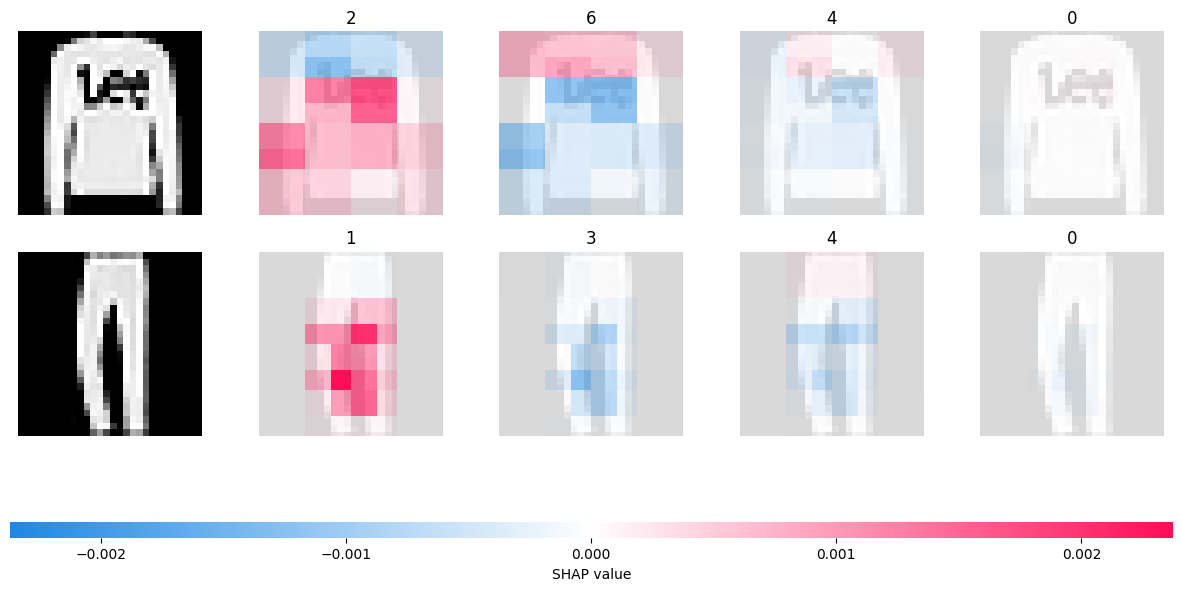

In [ ]:
# Here we explain two images using 200 evaluations of the underlying model, to estimate the SHAP values
shap_values = explainer(X_test[1:3], max_evals=200, batch_size=50, outputs=shap.Explanation.argsort.flip[:4])

# Rearrange the SHAP values into the list-of-arrays shape that shap.image_plot expects
shap_values.values = [val for val in np.moveaxis(shap_values.values, -1, 0)]

# Plot the SHAP values
shap.image_plot(shap_values=shap_values.values,
                 pixel_values=shap_values.data,
                 labels=shap_values.output_names)

### New Section: SHAP for Tabular Data (Optional/Learner-Friendly Example)

Since tabular data is often easier to interpret than images, let's look at how we apply SHAP to a classification task using a tabular dataset (the classic **Wine dataset** from `scikit-learn`).

We will:
1. Load the dataset.
2. Train a fast Tree-based model (Random Forest).
3. Compute SHAP values using `TreeExplainer`.
4. Visualize an individual prediction breakdown using a Waterfall plot.

In [ ]:
from sklearn.datasets import load_wine
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import shap

# 1. Load the tabular dataset
data = load_wine(as_frame=True)
X_tab = data.data
y_tab = data.target
feature_names = data.feature_names
target_names = data.target_names

# 2. Train a quick Random Forest Classifier
tab_model = RandomForestClassifier(n_estimators=50, random_state=42)
tab_model.fit(X_tab, y_tab)

print("Tabular model trained successfully!")
display(X_tab.head(3))

Tabular model trained successfully!


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0


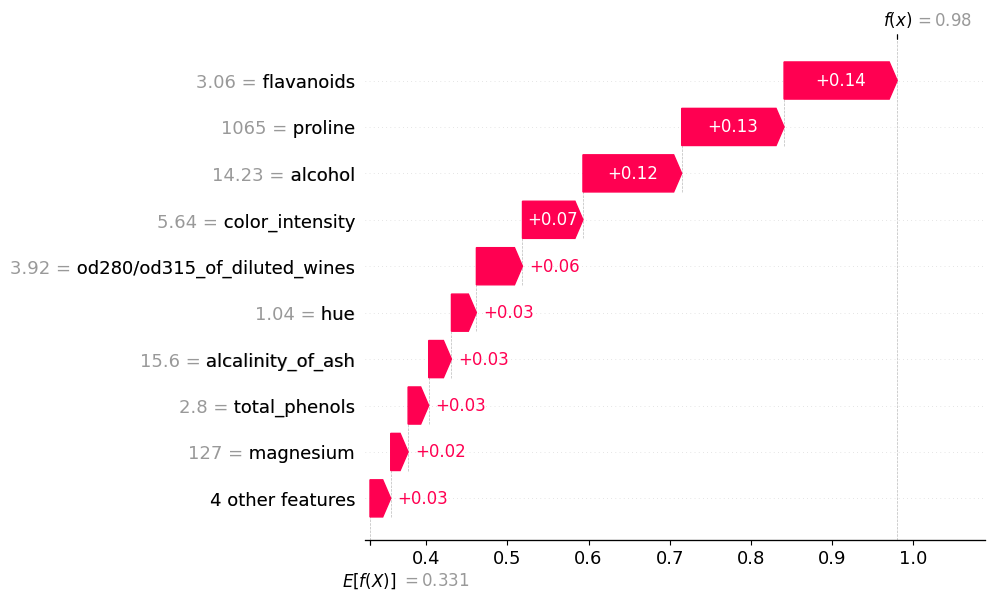

In [ ]:
# 3. Compute SHAP values specifically optimized for Tree models
tab_explainer = shap.TreeExplainer(tab_model)
tab_shap_values = tab_explainer(X_tab)

# Let's explain the very first instance in our dataset for the first class (Class 0)
# shap_values has shape: [num_samples, num_features, num_classes]
# We select sample 0, and class 0 output:
instance_index = 0
class_index = 0

# 4. Plot the breakdown using a waterfall plot
shap.plots.waterfall(tab_shap_values[instance_index, :, class_index])

**Observe**

Each row is one test image, and each column is one of the model's top 4 predicted classes for that image. Red pixels push the prediction toward that class, and blue pixels push it away. Unlike LIME's colored segments, SHAP assigns a signed number to every single pixel, which is what the underlying Shapley value framework promises: every input, down to the pixel, gets its fair share of credit or blame.

**Note for Instructor:** The original script's `max_evals=10000` is accurate but slow for a live class. `max_evals=200` with a coarse `blur(4,4)` masker produces a readable, if less fine-grained, plot in seconds. If time allows after class, rerun with `max_evals=5000` to see the explanation sharpen.

### SHAP Algorithm

In order to calculate SHAP (SHapley Additive exPlanations) values, we do the following:
- Choose a reference point as a baseline for feature contribution measurement.
- Explore all feature permutations for a specific instance.
- Evaluate each feature's contribution by comparing predictions with and without the feature.
- Apply the Shapley value formula to calculate feature importance.
- Interpret positive and negative SHAP values as positive and negative contributions.

SHAP values offer a comprehensive way to understand feature importance, accounting for interactions and dependencies, which aids the interpretation of complex models.

### AI-Assisted Comparison: LIME vs SHAP

We have now built both explainers by hand on the same dataset. Let's use an AI assistant to pressure-test what we think we know.

**Step 1:** Before asking the AI anything, write in the chat: one situation where you would reach for LIME, and one where you would reach for SHAP.

**Step 2:** Ask the AI assistant: "Compare LIME and SHAP for explaining a neural network's predictions. Cover speed, theoretical guarantees, and stability. Give one scenario where each is the better choice."

**Step 3:** Check the AI's answer against what we actually measured in this class: LIME's instability experiment, and the Shapley averaging formula with its $2^{n-1}$ cost. Does the AI's claim about stability match the swing we measured? Does its claim about speed match the `num_samples` versus `max_evals` trade-off we used in the code?

**Step 4:** Post in the chat one claim from the AI's answer that our own experiments actually back up, and one claim you cannot verify from what we did today.

**Note for Instructor:**
- AI role: produces a comparison summary from general knowledge.
- Learner role: fact-checks the summary against the two experiments run earlier in this class.
- Learning objective: use a hands-on result (the instability experiment) as a concrete check on a general claim, rather than accepting a plausible-sounding comparison at face value.
- Guardrail: a claim only counts as "backed up" if the learner can point to a specific number or plot from this notebook that supports it.

### Quiz: What SHAP Guarantees That LIME Does Not

**Question:** SHAP values for one prediction are guaranteed to add up exactly to (the model's output for that instance) minus (the average model output over a baseline). Why does this matter in practice?

- A. It guarantees that the top feature is always ranked first by LIME as well
- B. It guarantees that every SHAP explanation can be computed in constant time
- C. It removes any need to train the original black-box model in the first place
- D. The attributions become a complete, additive breakdown of the prediction

**Note for Instructor:** Run this as a chat poll. Correct option: D.

This additivity property, sometimes called local accuracy, means the SHAP values are not just a relative ranking of features: they are an actual decomposition of the prediction, and summing them exactly reconstructs the gap between this prediction and the baseline. LIME's weights carry no such guarantee. Additivity says nothing about computation time, and it does not remove the need for the original model, which SHAP still has to query.

### Interview Checkpoint: LIME vs SHAP

**Ask Learners:** An interviewer asks: "Your team can only adopt one explainability library for a healthcare model under regulatory review. LIME or SHAP, and why?" Type your answer in the chat.

**Note for Instructor:** Reveal the model answer after a few responses.
- Expected reasoning: a regulator wants explanations that are consistent and mathematically justified, which points to SHAP's additivity and its grounding in Shapley values. The trade-off is compute cost, since exact or near-exact SHAP values are more expensive than a LIME run, which matters if the model must be explained at high volume in real time.
- Common weak answer: "SHAP, because it's newer."
- Strong answer: names the additivity guarantee specifically, connects it to what a regulator or auditor would actually want (reproducible, decomposable explanations), and acknowledges the compute cost trade-off rather than treating the choice as free.

# Conclusion

- We have explored LIME and SHAP, two of the most popular techniques for model interpretability.
- We found that model interpretability can be an effective tool for transparency, debugging and bias mitigation in neural network architectures.

Let's connect this back to where we started.

**Ask Learners:** Go back to the diabetes prediction case at the start of class. In one sentence, how would you now answer the doctor who asks "why does the model say this patient has diabetes"? Type your answer in the chat.

- **LIME** answers that question quickly, for one patient, by perturbing the input and fitting a simple local model, but its answer can wobble unless you use enough samples.
- **SHAP** answers the same question more slowly, but with a mathematical guarantee that every feature's credit adds up exactly to the gap between this prediction and the baseline, which is what makes it the stronger choice when the explanation itself has to survive an audit.

Neither tool opens the model up and shows you its "true" reasoning. Both are approximations, built in different ways, with different guarantees and different costs. Choosing between them is itself a modeling decision, and now you know how to make it.